# ICT-4202 | Artificial Intelligence and Machine Learning Laboratory
## Final Laboratory Examination — Set 09
**Islamic University, Kushtia, Bangladesh**  
Department of Information and Communication Technology

> **Notebook purpose:** Question-matched solutions with brief background theory, mathematical notation, readable Python, reproducible output, interpretation, and viva revision. This is a learning/reporting notebook, not a claim of official model answers.

| Question | Topic | Marks |
|:--|:--|--:|
| Q1 | BFS versus DFS on branching graph | 30 |
| Q2 | A* and admissibility test | 30 |
| Q3 | K-means elbow/silhouette model selection | 30 |
| Q4 | Viva: shortest path, admissibility, inertia, silhouette | 10 |

**Execution:** Open in JupyterLab/VS Code, choose a Python kernel, then use **Run All**. All random experiments use a fixed seed. Markdown cells use MathJax (`$...$` and `$$...$$`) to render equations on GitHub/Jupyter.

**Quick access - one file per numbered question:** [Q1 / A](Set_09_A.py) | [Q2 / B](Set_09_B.py) | [Q3 / C](Set_09_C.py) | [Q4 / D: Viva practice](Set_09_D.py).

Q1-Q3 contain the required practical work (including all subparts). Q4 is a viva, so its `.py` file is a revision/self-quiz tool, not an extra algorithm assignment. This notebook contains solutions, explanations, mathematical theory, and the Q4 viva questions.

---
## Q1. BFS and DFS Comparison (30 marks)
**Question specification**  
`A→{B,C}, B→{D,E}, C→{F}, D→{H}, E→{G}, F→{G}, G→{}, H→{G}`. Find A to G by BFS and DFS, print paths and expansion traces. Reverse adjacency order and compare. Explain why BFS finds a minimum-edge route.

### Theory and mathematical background
For an unweighted graph, **BFS** expands the shallowest frontier state first (FIFO queue), so it finds a minimum-edge path when each edge has equal cost. **DFS** explores a branch deeply first (LIFO stack), so its outcome depends on neighbor order. A **visited set** prevents re-expansion.

With $V$ vertices and $E$ edges, BFS and DFS can both run in $O(V+E)$ time on an adjacency-list graph; their frontier sizes and discovered-node storage differ. In tree-search notation, BFS typically uses $O(b^{d+1})$ space, while DFS uses $O(bm)$ space ($b$ branching factor, $d$ shallowest goal depth, $m$ maximum depth). These are different models of complexity.

In [1]:
from collections import deque

import heapq

from itertools import count

def bfs(graph, start, goal):
    queue = deque([(start, [start])])
    seen = {start}
    expanded = []
    while queue:
        node, path = queue.popleft()
        expanded.append(node)
        if node == goal:
            return path, expanded
        for nxt in graph.get(node, []):
            if nxt not in seen:
                seen.add(nxt)
                queue.append((nxt, path + [nxt]))
    return None, expanded

def dfs(graph, start, goal):
    stack = [(start, [start])]
    seen = set()
    expanded = []
    while stack:
        node, path = stack.pop()
        if node in seen: continue
        seen.add(node)
        expanded.append(node)
        if node == goal:
            return path, expanded
        # Reverse push order so the FIRST listed neighbor is explored first.
        for nxt in reversed(graph.get(node, [])):
            if nxt not in seen:
                stack.append((nxt, path + [nxt]))
    return None, expanded

graph={'A':['B','C'],'B':['D','E'],'C':['F'],'D':['H'],
       'E':['G'],'F':['G'],'G':[],'H':['G']}
reversed_graph={u:list(reversed(v)) for u,v in graph.items()}
for name, variant in [('Original adjacency',graph),('Reversed adjacency',reversed_graph)]:
    print('\n'+name)
    for algorithm,fn in [('BFS',bfs),('DFS',dfs)]:
        path,expanded=fn(variant,'A','G')
        print(f'  {algorithm}: path={path}; edges={len(path)-1 if path else None}; expanded={expanded}')



Original adjacency
  BFS: path=['A', 'B', 'E', 'G']; edges=3; expanded=['A', 'B', 'C', 'D', 'E', 'F', 'H', 'G']
  DFS: path=['A', 'B', 'D', 'H', 'G']; edges=4; expanded=['A', 'B', 'D', 'H', 'G']

Reversed adjacency
  BFS: path=['A', 'C', 'F', 'G']; edges=3; expanded=['A', 'C', 'B', 'F', 'E', 'D', 'G']
  DFS: path=['A', 'C', 'F', 'G']; edges=3; expanded=['A', 'C', 'F', 'G']


### Result interpretation and discussion
BFS processes all paths of depth $d$ before any at depth $d+1$, so for equal edge weights the first goal reached has the fewest edges. Changing the adjacency order can change **which** equal-depth route is returned. DFS may instead explore an additional deep detour through `D→H` before returning to other branches.

---
## Q2. A* and Heuristic Admissibility (30 marks)
**Question specification**  
`S-A=1, S-B=5, A-C=2, A-D=4, B-D=1, C-G=5, D-G=2`. Choose an admissible heuristic, show g/h/f and best route. Make one heuristic overestimate and discuss why admissibility matters.

### Theory and mathematical background
A heuristic $h(n)$ estimates remaining cost from state $n$ to the goal. **Greedy best-first search** prioritizes only $h(n)$, so it need not find the lowest-cost route.

**A\* search** uses
$$g(n)=\text{cost from start to }n,\qquad f(n)=g(n)+h(n).$$
A heuristic is **admissible** when
$$0\le h(n)\le h^*(n),$$
where $h^*(n)$ is the true cheapest remaining cost. Under suitable graph-search conditions, admissible heuristics with cost updates/reopening allow optimal A\*; non-admissible heuristics remove this guarantee.

In [2]:
from itertools import count

import heapq

def astar(graph, h, start, goal):
    counter = count()
    heap = [(h[start], next(counter), 0, start, [start])]
    best_g = {start: 0}
    expanded = []
    while heap:
        f, _, g, node, path = heapq.heappop(heap)
        if g > best_g.get(node, float('inf')): continue  # stale entry
        expanded.append((node, g, h[node], f))
        if node == goal: return path, g, expanded
        for nxt, weight in graph.get(node, []):
            new_g = g + weight
            if new_g < best_g.get(nxt, float('inf')):
                best_g[nxt] = new_g
                heapq.heappush(heap, (new_g+h[nxt], next(counter), new_g, nxt, path+[nxt]))
    return None, float('inf'), expanded

def display_astar_trace(trace):
    print("Node     g(n)     h(n)     f(n)")
    for node, g, h, f in trace:
        print(f"{node:>4} {g:>8} {h:>8} {f:>8}")

graph={'S':[('A',1),('B',5)],'A':[('C',2),('D',4)],
       'B':[('D',1)],'C':[('G',5)],'D':[('G',2)],'G':[]}
# True remaining costs: S=7, A=6, B=3, C=5, D=2, G=0.
# The base heuristic never overestimates these true values.
h={'S':6,'A':5,'B':3,'C':4,'D':2,'G':0}
true_to_goal={'S':7,'A':6,'B':3,'C':5,'D':2,'G':0}
print('Admissibility check (h <= optimal remaining cost):')
for node in h:
    print(node,'h=',h[node],'true remaining=',true_to_goal[node],
          'admissible=',h[node]<=true_to_goal[node])
optimal_path,optimal_cost,trace=astar(graph,h,'S','G')
print('\nA* with admissible h:',optimal_path,'| total cost:',optimal_cost)
display_astar_trace(trace)
bad_h=dict(h);bad_h['A']=100  # deliberately overestimates A's true cost-to-go (6)
bad_path,bad_cost,bad_trace=astar(graph,bad_h,'S','G')
print('A* with nonadmissible h(A)=100:',bad_path,'| total cost:',bad_cost)
display_astar_trace(bad_trace)
assert optimal_cost==7
assert bad_cost>=optimal_cost


Admissibility check (h <= optimal remaining cost):
S h= 6 true remaining= 7 admissible= True
A h= 5 true remaining= 6 admissible= True
B h= 3 true remaining= 3 admissible= True
C h= 4 true remaining= 5 admissible= True
D h= 2 true remaining= 2 admissible= True
G h= 0 true remaining= 0 admissible= True

A* with admissible h: ['S', 'A', 'D', 'G'] | total cost: 7
Node     g(n)     h(n)     f(n)
   S        0        6        6
   A        1        5        6
   C        3        4        7
   D        5        2        7
   G        7        0        7
A* with nonadmissible h(A)=100: ['S', 'B', 'D', 'G'] | total cost: 8
Node     g(n)     h(n)     f(n)
   S        0        6        6
   B        5        3        8
   D        6        2        8
   G        8        0        8


### Result interpretation and discussion
For the admissible heuristic, optimal route `S→A→D→G` costs $1+4+2=7$. Choosing $h(A)=100$ **overestimates** the actual remaining cost (6) and can cause A* to return the inferior `S→B→D→G` cost 8 before exploring A. An overestimate does not always change the answer, but it removes the usual optimality guarantee; this graph provides a concrete counterexample.

---
## Q3. K-means Model Selection (30 marks)
**Question specification**  
First two Iris features, $k=2,3,4,5$. Tabulate inertia and silhouette; plot an elbow curve and silhouette by $k$; choose a $k$ and display final clusters/centers. Explain why inertia usually decreases as $k$ grows.

### Theory and mathematical background
**K-means** is an unsupervised clustering method that alternates assigning samples to the nearest centroid and updating centroids. For $K$ clusters, it seeks to minimize
$$J=\sum_{i=1}^{n}\left\|\mathbf x_i-\boldsymbol\mu_{z_i}\right\|_2^2.$$
`inertia_` is the final within-cluster sum of squares. The silhouette of a sample is
$$s(i)=\frac{b(i)-a(i)}{\max\{a(i),b(i)\}},$$
where $a(i)$ is average within-cluster distance and $b(i)$ is its smallest mean distance to another cluster. Larger silhouette generally indicates better-separated clusters. **Cluster IDs are arbitrary** and are not species class labels.

Feature scaling changes the distance geometry and inertia's units; compare inertia only for models using comparable feature representations.

 k  inertia  silhouette
 2  58.2041      0.4630
 3  37.0507      0.4451
 4  27.9902      0.4249
 5  20.9968      0.4101


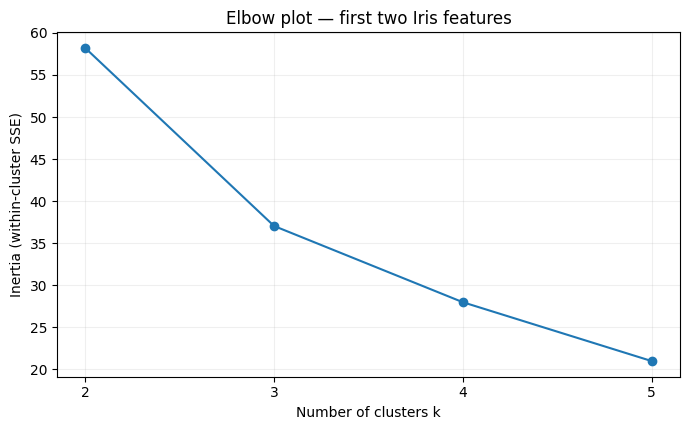

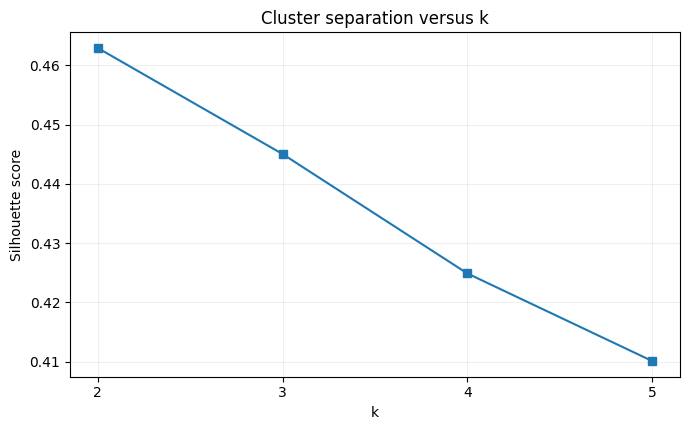

Chosen by maximum silhouette: 2
Centers:
 [[5.224 3.131]
 [6.61  2.966]]


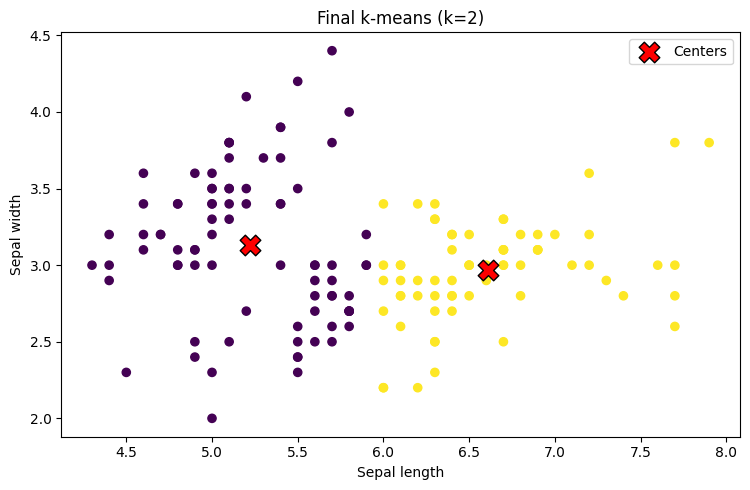

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler
iris = load_iris()

X=iris.data[:, :2]
runs=[]; models={}
for k in [2,3,4,5]:
    mdl=KMeans(n_clusters=k,random_state=42,n_init=10).fit(X)
    models[k]=mdl
    runs.append({'k':k,'inertia':mdl.inertia_,'silhouette':silhouette_score(X,mdl.labels_)})
table=pd.DataFrame(runs)
print(table.round(4).to_string(index=False))
chosen_k=int(table.loc[table.silhouette.idxmax(),'k'])
best=models[chosen_k]
plt.figure(figsize=(7,4.4))
plt.plot(table.k,table.inertia,marker='o');plt.xticks([2,3,4,5]);plt.xlabel('Number of clusters k')
plt.ylabel('Inertia (within-cluster SSE)');plt.title('Elbow plot — first two Iris features')
plt.grid(alpha=.2);plt.tight_layout();plt.show()
plt.figure(figsize=(7,4.4))
plt.plot(table.k,table.silhouette,marker='s');plt.xticks([2,3,4,5]);plt.xlabel('k')
plt.ylabel('Silhouette score');plt.title('Cluster separation versus k')
plt.grid(alpha=.2);plt.tight_layout();plt.show()
print('Chosen by maximum silhouette:',chosen_k)
print('Centers:\n',best.cluster_centers_.round(3))
plt.figure(figsize=(7.6,5))
plt.scatter(X[:,0],X[:,1],c=best.labels_,cmap='viridis',s=35)
plt.scatter(best.cluster_centers_[:,0],best.cluster_centers_[:,1],marker='X',s=220,
            edgecolors='black',c='red',label='Centers')
plt.xlabel('Sepal length');plt.ylabel('Sepal width');plt.title(f'Final k-means (k={chosen_k})')
plt.legend();plt.tight_layout();plt.show()


### Result interpretation and discussion
Adding clusters gives the algorithm more centroids and (at a global optimum) cannot increase the smallest possible within-cluster SSE. Practical K-means may converge to local minima, so individual initialization choices need not be monotonic, but the reported values with consistent settings should typically decline. Silhouette balances compactness and separation.

---
## Q4. Viva voce (10 marks)

| Question | Concise answer |
|:--|:--|
| Why BFS returns a shortest path? | FIFO exploration of increasing depth in an unweighted graph. |
| Can DFS give a longer path? | Yes; DFS does not prioritize depth globally. |
| Admissible heuristic? | h never overestimates the true remaining cheapest cost. |
| A* priority? | f(n)=g(n)+h(n). |
| What is inertia? | Sum of within-cluster squared deviations. |
| What is an elbow? | A point where inertia improvement slows markedly. |
| What does silhouette measure? | Similarity within the assigned cluster versus nearest other cluster. |

| What happens if a heuristic overestimates the cost? | A* may lose its shortest-cost guarantee because the heuristic is not admissible. |
| Why does K-means inertia usually decrease as k increases? | More centers can reduce or preserve the sum of distances to the nearest assigned center. |

**Review tip:** Explain the code by identifying the inputs, data structures, stopping conditions, evaluation metrics, and one limitation for each task.

---
### Submission checklist
- [ ] Execute every Python cell in sequence; check the saved output is current.
- [ ] Explain the main formula, trace, and interpretation for Q1, Q2, Q3.
- [ ] Record the original task settings, dataset, random seed, and actual test metrics.
- [ ] For WEKA tasks, run WEKA locally and attach the real result-buffer output/screenshot; notebook instructions **do not substitute for WEKA evidence**.
- [ ] Be ready to discuss one methodological limitation in viva.

**Integrity note:** Code and explanations are independently written for this study repository. Numeric results are calculated from the shown code and may vary with library versions where numerical or tie-breaking differences occur.